# 05 · Backtest and SARIMA

**Backtest:** an expanding-window check that LightGBM's advantage is stable across years rather than a lucky test split. Each fold trains on everything before its test window (no shuffling) and uses the hyperparameters found in notebook 04.

**SARIMA:** a classical statistical reference fitted on *daily peak load* (hourly SARIMA is too slow). It is compared on daily peak error only, so it lives in this notebook and the README, not in `mart.fact_forecast`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [2]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit
from src.config import BACKTEST_FOLDS, BACKTEST_TEST_SIZE, TRAIN_END, VALID_END
from src.db import get_engine
from src.features import load_features, add_groups
from src.evaluate import score
from src.train import fit_fixed, make_xy

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "docs" / "results"; RES.mkdir(parents=True, exist_ok=True)

df = add_groups(load_features())
print(df.shape)

(145201, 28)


## 1 · Expanding-window backtest

In [3]:
params = json.load(open(RES / "lightgbm_best_params.json"))
n_est = params.pop("n_estimators")

tscv = TimeSeriesSplit(n_splits=BACKTEST_FOLDS, test_size=BACKTEST_TEST_SIZE)
rows = []
for k, (tr, te) in enumerate(tscv.split(df), start=1):
    train_k, test_k = df.iloc[tr], df.iloc[te].copy()
    model = fit_fixed(train_k, params, n_est)
    test_k["lightgbm"] = model.predict(make_xy(test_k)[0])
    test_k["seasonal_naive"] = test_k["load_lag_168h"]
    test_k["same_hour_yesterday"] = test_k["load_lag_24h"]
    for name in ["seasonal_naive", "same_hour_yesterday", "lightgbm"]:
        rows.append({"fold": k, "model": name, "train_hours": len(tr),
                     "test_start": test_k["ts"].min().date(), "test_end": test_k["ts"].max().date(),
                     **score(test_k, name)})
    print(f"fold {k}: trained on {len(tr):,} hours, tested {test_k['ts'].min().date()} -> {test_k['ts'].max().date()}")
bt = pd.DataFrame(rows)
bt.to_csv(RES / "backtest_metrics.csv", index=False)

fold 1: trained on 92,641 hours, tested 2012-08-04 -> 2013-08-04
fold 2: trained on 101,401 hours, tested 2013-08-04 -> 2014-08-04
fold 3: trained on 110,161 hours, tested 2014-08-04 -> 2015-08-04
fold 4: trained on 118,921 hours, tested 2015-08-04 -> 2016-08-03
fold 5: trained on 127,681 hours, tested 2016-08-03 -> 2017-08-03
fold 6: trained on 136,441 hours, tested 2017-08-03 -> 2018-08-03


In [4]:
wape = bt.pivot(index="fold", columns="model", values="WAPE_%")
wape["window"] = bt[bt["model"] == "lightgbm"].set_index("fold").apply(lambda r: f"{r['test_start']} -> {r['test_end']}", axis=1)
wape["lgbm_vs_seasonal_naive_%"] = (1 - wape["lightgbm"] / wape["seasonal_naive"]) * 100
wape["lgbm_vs_yesterday_%"] = (1 - wape["lightgbm"] / wape["same_hour_yesterday"]) * 100
wape.round(2)

model,lightgbm,same_hour_yesterday,seasonal_naive,window,lgbm_vs_seasonal_naive_%,lgbm_vs_yesterday_%
fold,,,,,,
1,2.75,6.48,9.42,2012-08-04 -> 2013-08-04,70.75,57.48
2,2.75,7.54,10.40,2013-08-04 -> 2014-08-04,73.52,63.51
3,2.76,7.10,10.03,2014-08-04 -> 2015-08-04,72.46,61.13
4,2.64,6.53,9.71,2015-08-04 -> 2016-08-03,72.86,59.61
5,2.94,6.99,11.20,2016-08-03 -> 2017-08-03,73.73,57.89
6,3.13,7.39,11.48,2017-08-03 -> 2018-08-03,72.74,57.67


LightGBM beat the seasonal-naive baseline in 6 of 6 folds
LightGBM beat same-hour-yesterday in 6 of 6 folds
mean WAPE: lightgbm 2.83%  (std 0.18)


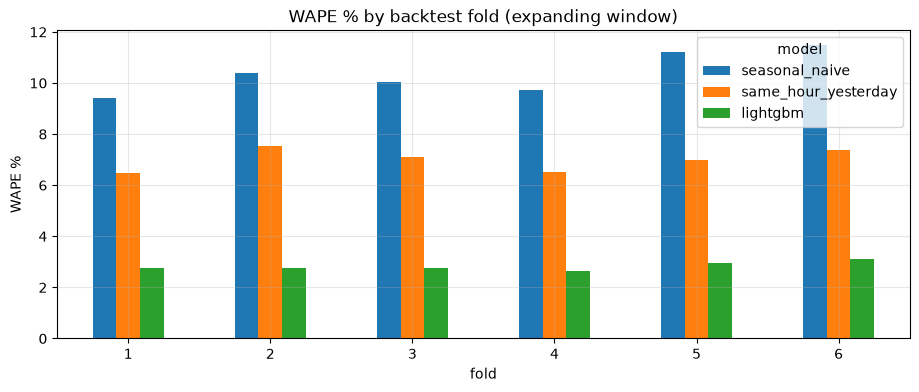

In [5]:
fig, ax = plt.subplots()
wape[["seasonal_naive", "same_hour_yesterday", "lightgbm"]].plot.bar(ax=ax, rot=0)
ax.set(title="WAPE % by backtest fold (expanding window)", ylabel="WAPE %")
fig.savefig(FIG / "backtest_wape.png", dpi=150, bbox_inches="tight")
print("LightGBM beat the seasonal-naive baseline in", int((wape["lightgbm"] < wape["seasonal_naive"]).sum()), "of", len(wape), "folds")
print("LightGBM beat same-hour-yesterday in", int((wape["lightgbm"] < wape["same_hour_yesterday"]).sum()), "of", len(wape), "folds")
print(f"mean WAPE: lightgbm {wape['lightgbm'].mean():.2f}%  (std {wape['lightgbm'].std():.2f})")

## 2 · SARIMA on daily peak load

One-step-ahead forecasts: each day's peak is predicted from all earlier days (no peeking), which is what a day-ahead forecast would know.

In [6]:
full_days = df.groupby("date").filter(lambda g: len(g) == 24)       # drop the partial last day
daily = full_days.groupby("date")["load_mw"].max()
daily.index = pd.DatetimeIndex(daily.index)
daily = daily.asfreq("D")
print(f"{len(daily)} days, {int(daily.isna().sum())} missing")

train_daily = daily[:TRAIN_END].interpolate()
sarima = sm.tsa.SARIMAX(train_daily, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7),
                        enforce_stationarity=False, enforce_invertibility=False)
res = sarima.fit(disp=False, maxiter=200)
print(res.summary().tables[1])

6050 days, 0 missing
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8266      0.007    124.339      0.000       0.814       0.840
ma.L1          0.2073      0.011     19.306      0.000       0.186       0.228
ar.S.L7        0.0216      0.012      1.799      0.072      -0.002       0.045
ma.S.L7       -0.8808      0.005   -164.946      0.000      -0.891      -0.870
sigma2      7.282e+06   1.03e+05     70.952      0.000    7.08e+06    7.48e+06


In [7]:
res_full = res.apply(daily.interpolate())          # same parameters, now sees the whole series
start = daily.index[daily.index > pd.Timestamp(TRAIN_END)][0]
pred = res_full.get_prediction(start=start, dynamic=False).predicted_mean   # one-step-ahead

peaks = pd.DataFrame({"actual": daily[start:], "sarima": pred})
peaks["split"] = np.where(peaks.index <= pd.Timestamp(VALID_END), "validation", "test")

# the same daily peaks implied by the hourly models
q = """SELECT f.ts::date AS date, m.model_name, f.split, max(f.forecast_mw) AS fc_peak
       FROM mart.fact_forecast f JOIN mart.dim_model m USING (model_key)
       WHERE f.split IN ('validation', 'test') GROUP BY 1, 2, 3"""
db_peaks = pd.read_sql(q, get_engine(), parse_dates=["date"]).pivot_table(index="date", columns="model_name", values="fc_peak")
peaks = peaks.join(db_peaks)
by_day = df.groupby("date")
peaks["same_hour_yesterday"] = by_day["load_lag_24h"].max().reindex(peaks.index)
peaks = peaks.dropna(subset=["actual", "sarima", "seasonal_naive"])
peaks.tail(3)

,actual,sarima,split,lightgbm,prophet,seasonal_naive,same_hour_yesterday
date,,,,,,,
2018-07-31,42011.0,37533.567737,test,42662.72,42291.85,44989.0,37671.0
2018-08-01,49308.0,40783.919727,test,48788.27,46863.99,43279.0,42011.0
2018-08-02,47154.0,51286.422439,test,50787.00,45642.09,49029.0,49308.0


In [8]:
models = [c for c in ["sarima", "seasonal_naive", "same_hour_yesterday", "prophet", "lightgbm"] if c in peaks.columns]
rows = []
for s in ["validation", "test"]:
    p = peaks[peaks["split"] == s].dropna(subset=models)
    for m in models:
        err = p[m] - p["actual"]
        rows.append({"model": m, "split": s, "peak_MAE_MW": err.abs().mean(), "peak_bias_MW": err.mean(),
                     "peak_MAPE_%": (err.abs() / p["actual"]).mean() * 100, "n_days": len(p)})
peak_tbl = pd.DataFrame(rows).round(1)
peak_tbl.to_csv(RES / "daily_peak_comparison.csv", index=False)
peak_tbl.pivot(index="model", columns="split", values="peak_MAE_MW")

split,test,validation
model,,
lightgbm,1123.5,864.8
prophet,2052.4,1904.2
same_hour_yesterday,2611.9,2265.3
sarima,2220.8,2011.3
seasonal_naive,4384.4,4033.5
